In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import xgboost
print("Tout fonctionne, sklearn", sklearn.__version__)

Tout fonctionne, sklearn 1.6.1


# F3. Prévision de l'inflation

**Nom et prénom :** Raoufi Nouhaila    **Code Apogée :** 25007620    **Groupe :** FIN3    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/Nouhaila-25/25007620-nouhaila-raoufi-FIN3

## 1. Sujet et problématique
- **Intérêt du sujet** : L'inflation guide les décisions des banques centrales (taux directeur), des entreprises (prix, salaires) et des investisseurs (placements obligataires). Savoir si le chômage et le taux directeur aident à l'anticiper est utile pour ces décisions.
- **Problématique** : Le taux de chômage et le taux directeur permettent-ils de prévoir l'inflation américaine (variation annuelle de l'indice des prix) 12 mois à l'avance mieux qu'une simple règle naïve ?
- **Objectif mesurable** : Obtenir un RMSE inférieur d'au moins 10 % à celui de la règle « inflation dans 12 mois = inflation actuelle », sur les 60 derniers mois (jeu de test), avec un écart de 12 mois entre apprentissage et test.
- **Nature du problème** : Régression sur séries temporelles mensuelles, car la variable à prédire (le taux d'inflation) est numérique continue et les données sont ordonnées dans le temps.
- **Algorithme principal envisagé** : n°2, Ridge. Régression linéaire pénalisée, adaptée à peu de variables corrélées entre elles (retards successifs). Je n'ai pas retenu le gradient boosting (n°7) : environ 950 observations seulement, et les arbres n'extrapolent pas au-delà des valeurs vues à l'apprentissage.

In [2]:
!git clone https://github.com/Nouhaila-25/25007620-nouhaila-raoufi-FIN3.git

Cloning into '25007620-nouhaila-raoufi-FIN3'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 46 (delta 10), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 26.15 KiB | 2.90 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, sys

GRAINE = 42
np.random.seed(GRAINE)

RACINE = Path("25007620-nouhaila-raoufi-FIN3")
RAW = RACINE / "data" / "raw"

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print([str(p) for p in RAW.rglob("*") if p.is_file()])

Python 3.13.18 | pandas 2.2.3 | sklearn 1.6.1
['25007620-nouhaila-raoufi-FIN3/data/raw/FEDFUNDS.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/UNRATE.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/CPIAUCSL.csv', '25007620-nouhaila-raoufi-FIN3/data/raw/.gitkeep']


In [6]:
series = {}
for f in RAW.glob("*.csv"):
    df = pd.read_csv(f)
    nom = df.columns[1]
    df.columns = ["date", nom]
    df["date"] = pd.to_datetime(df["date"])
    df[nom] = pd.to_numeric(df[nom], errors="coerce")
    series[nom] = df.set_index("date")
    print(f.name, "->", nom)

cpi = series["CPIAUCSL"]
chom = series["UNRATE"]
taux = series["FEDFUNDS"]

for nom, d in [("CPIAUCSL", cpi), ("UNRATE", chom), ("FEDFUNDS", taux)]:
    print(nom, d.shape, d.index.min().date(), "->", d.index.max().date(), "| manquants :", int(d.iloc[:, 0].isna().sum()))
    display(d.head(3))

FEDFUNDS.csv -> FEDFUNDS
UNRATE.csv -> UNRATE
CPIAUCSL.csv -> CPIAUCSL
CPIAUCSL (958, 1) 1947-01-01 -> 2026-10-01 | manquants : 1


,CPIAUCSL
date,
1947-01-01,21.48
1947-02-01,21.62
1947-03-01,22.00


UNRATE (946, 1) 1948-01-01 -> 2026-10-01 | manquants : 1


,UNRATE
date,
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0


FEDFUNDS (868, 1) 1954-07-01 -> 2026-10-01 | manquants : 0


,FEDFUNDS
date,
1954-07-01,0.80
1954-08-01,1.22
1954-09-01,1.07


In [7]:
df = cpi.join(chom, how="inner").join(taux, how="inner")
df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100   # variation annuelle en %

print(df.shape, df.index.min().date(), "->", df.index.max().date(), "| fréquence :", pd.infer_freq(df.index))
print("Doublons de dates :", df.index.duplicated().sum(), "| dates triées :", df.index.is_monotonic_increasing)
print(df.isna().sum())
display(df.describe().round(2))

(868, 4) 1954-07-01 -> 2026-10-01 | fréquence : MS
Doublons de dates : 0 | dates triées : True
CPIAUCSL      1
UNRATE        1
FEDFUNDS      0
inflation    12
dtype: int64


/tmp/ipykernel_6811/1482388109.py:2: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100   # variation annuelle en %


,CPIAUCSL,UNRATE,FEDFUNDS,inflation
count,867.00,867.00,868.00,856.00
mean,136.52,5.79,4.59,3.62
std,89.55,1.67,3.52,2.74
min,26.71,3.40,0.05,-1.96
25%,41.85,4.40,1.94,1.76
50%,131.60,5.50,4.24,2.96
75%,213.09,6.85,6.10,4.39
max,337.48,14.80,19.10,14.59


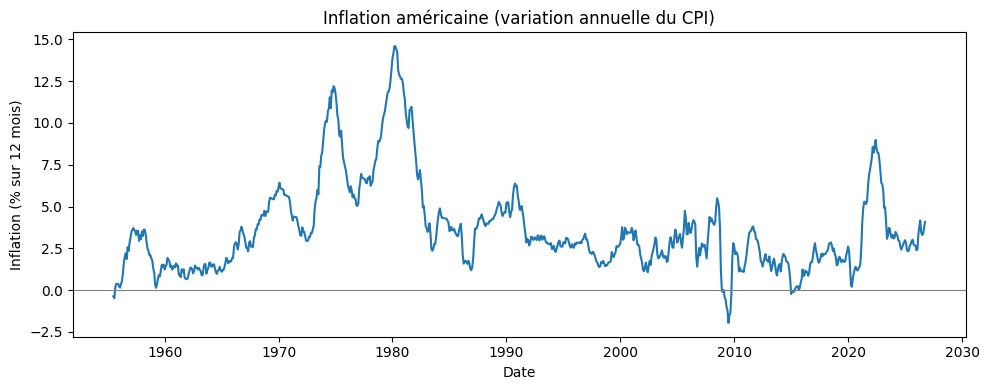

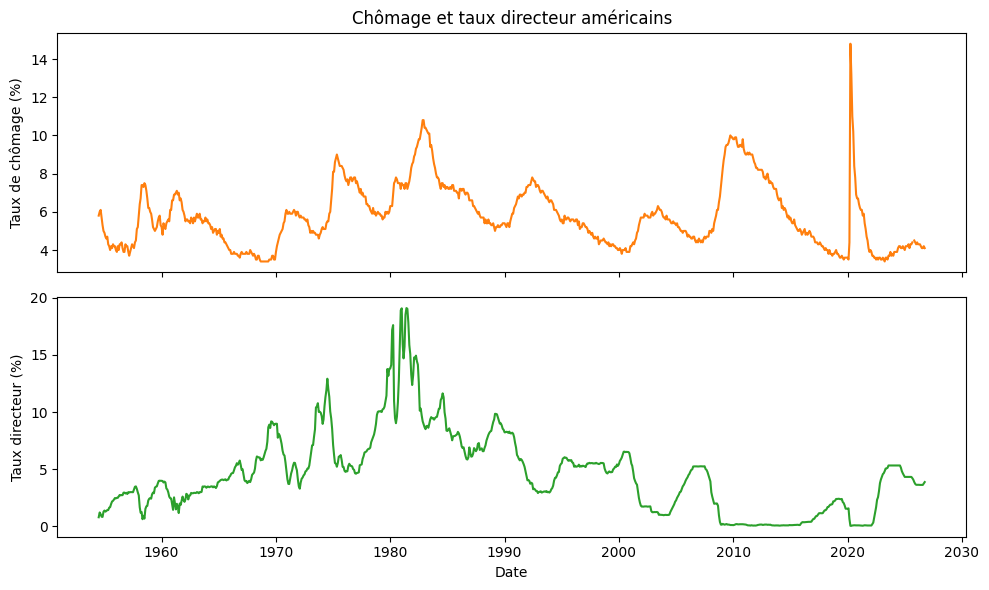

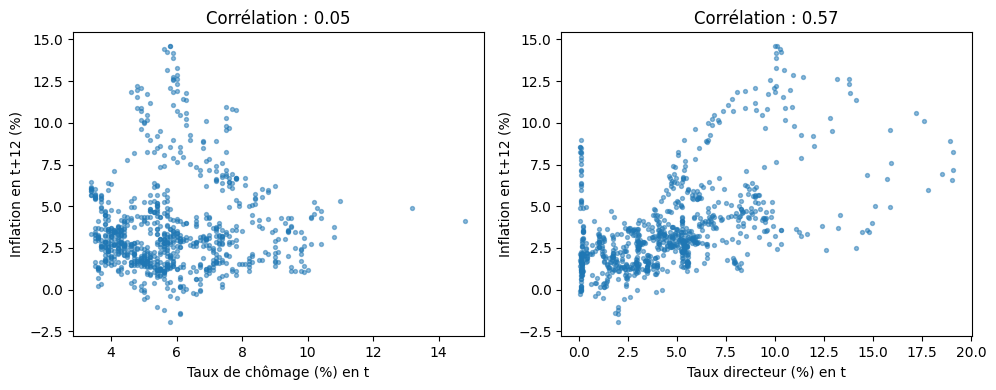

In [8]:
(RACINE / "figures").mkdir(exist_ok=True)

# Graphique 1 : inflation
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df["inflation"])
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Inflation américaine (variation annuelle du CPI)")
ax.set_xlabel("Date"); ax.set_ylabel("Inflation (% sur 12 mois)")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g1_inflation.png", dpi=150); plt.show()

# Graphique 2 : chômage et taux directeur
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(df.index, df["UNRATE"], color="tab:orange")
axes[0].set_ylabel("Taux de chômage (%)")
axes[1].plot(df.index, df["FEDFUNDS"], color="tab:green")
axes[1].set_ylabel("Taux directeur (%)"); axes[1].set_xlabel("Date")
axes[0].set_title("Chômage et taux directeur américains")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g2_chomage_taux.png", dpi=150); plt.show()

# Graphique 3 : variables d'aujourd'hui contre inflation dans 12 mois
futur = df["inflation"].shift(-12)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, v, lab in zip(axes, ["UNRATE", "FEDFUNDS"], ["Taux de chômage (%)", "Taux directeur (%)"]):
    ok = futur.notna() & df[v].notna()
    ax.scatter(df.loc[ok, v], futur[ok], s=8, alpha=0.5)
    ax.set_xlabel(lab + " en t"); ax.set_ylabel("Inflation en t+12 (%)")
    ax.set_title(f"Corrélation : {df.loc[ok, v].corr(futur[ok]):.2f}")
plt.tight_layout(); plt.savefig(RACINE / "figures" / "g3_relations.png", dpi=150); plt.show()

In [9]:
variables = ["inflation", "UNRATE", "FEDFUNDS"]
X = pd.DataFrame(index=df.index)
for v in variables:
    for k in [0, 3, 6, 12]:
        X[f"{v}_t-{k}"] = df[v].shift(k)            # shift positif = passé seulement

y = df["inflation"].shift(-12).rename("inflation_t+12")   # cible : inflation dans 12 mois

data = pd.concat([X, y], axis=1).dropna()
X, y = data.drop(columns="inflation_t+12"), data["inflation_t+12"]

# Preuve d'alignement
d = data.index[10]
print("Date t :", d.date())
print("Inflation réelle 12 mois plus tard :", round(df.loc[d + pd.DateOffset(months=12), "inflation"], 4))
print("Cible dans le tableau              :", round(data.loc[d, "inflation_t+12"], 4))
display(data[["inflation_t-0", "UNRATE_t-0", "FEDFUNDS_t-0", "inflation_t+12"]].head(3))
print(X.shape)

Date t : 1957-05-01
Inflation réelle 12 mois plus tard : 3.3571
Cible dans le tableau              : 3.3571


,inflation_t-0,UNRATE_t-0,FEDFUNDS_t-0,inflation_t+12
date,,,,
1956-07-01,1.980568,4.4,2.75,3.297911
1956-08-01,2.208084,4.1,2.73,3.551813
1956-09-01,1.862197,3.9,2.95,3.546618


(831, 12)


In [10]:
N_TEST, GAP = 60, 12
i_test = len(data) - N_TEST
i_fin_train = i_test - GAP

X_train, y_train = X.iloc[:i_fin_train], y.iloc[:i_fin_train]
X_test, y_test = X.iloc[i_test:], y.iloc[i_test:]

print("Apprentissage :", X_train.index.min().date(), "->", X_train.index.max().date(), f"({len(X_train)} mois)")
print("Écart ignoré  :", X.index[i_fin_train].date(), "->", X.index[i_test - 1].date(), f"({GAP} mois)")
print("Test          :", X_test.index.min().date(), "->", X_test.index.max().date(), f"({len(X_test)} mois)")

Apprentissage : 1956-07-01 -> 2019-09-01 (759 mois)
Écart ignoré  : 2019-10-01 -> 2020-09-01 (12 mois)
Test          : 2020-10-01 -> 2025-09-01 (60 mois)


« Préparation »

les variables créées et leurs formules (inflation = variation sur 12 mois du CPI ; retards 0, 3, 6, 12 mois ; cible = inflation à t+12) ;

la prévention des fuites : retards avec shift positif, cible décalée vers le futur, lignes incomplètes retirées, écart de 12 mois entre apprentissage et test parce que la cible porte sur 12 mois, pas de mélange aléatoire ;

la standardisation : nécessaire pour Ridge (la pénalité dépend de l’échelle des variables), faite dans un Pipeline, donc ajustée sur l’apprentissage seulement.